**08 | Full Development-Cohort Audit**

![Notebook 08 horizontal workflow](../images/08_workflow.svg)

**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**Objective:** Examine all 29 official HARTH v2.0 participants outside the original S023/S032 reserved Test set. Audit label availability and possible GroupKFold partitions **before** more expensive training. No model is fitted and Test data are not loaded.

**Download note:** 19 additional source CSVs total approximately 775 MiB, so review the inventory before permitting downloads. Cached data stay local and Git-ignored.

**01. Imports and dataset inventory**

In [1]:
# ==================== 01. Imports and dataset inventory ====================
# 1. Follow the documented imports and dataset inventory procedure with the established dataset and checks.

# ------------------------------------------------------------
# 1) Python Standard Library
# ------------------------------------------------------------
import sys
from pathlib import Path
# ------------------------------------------------------------
# 2) Data and Machine Learning
# ------------------------------------------------------------
import numpy as np
import pandas as pd
# ------------------------------------------------------------
# 3) Visualisation and Display
# ------------------------------------------------------------
import matplotlib.pyplot as plt
from IPython.display import display

# Import the existing study adapter and shared group-coverage audit.
root = Path.cwd().resolve()
while not (root / "code/python/src/core/data_loading.py").is_file():
    if root == root.parent:
        raise RuntimeError("Open this notebook from within the repository.")
    root = root.parent
sys.path.insert(0, str(root / "code/python/src"))
sys.path.insert(0, str(root / "studies/wearable_activity_recognition/src"))
# ------------------------------------------------------------
# 5) Project Utilities
# ------------------------------------------------------------
from harth_data import HARTH_SUBJECTS, ACTIVITY_NAMES, prepare_harth_feature_cohort
from core.data_splitting import audit_group_class_coverage
print("Project:", root)

Project: D:\human-movement-intelligence


**02. Inspect the download requirements before starting**

The two previously reserved Test subjects are excluded by identifier. Run this cell and check the file inventory. The next cell performs downloads; it is deliberately separate.

In [2]:
# ==================== 02. Inspect the download requirements before starting ====================
# 1. Follow the documented inspect the download requirements before starting procedure with the established dataset and checks.

# Freeze original Test IDs; never add them to the development cohort.
RESERVED_TEST = {"S023", "S032"}
DEVELOPMENT_SUBJECTS = sorted(set(HARTH_SUBJECTS) - RESERVED_TEST)
TASK_CLASSES = tuple(range(1, 9))
data_dir = root / "data/raw/harth_v2"
inventory = pd.DataFrame([
    {"subject": subject,
     "locally_cached": (data_dir / f"{subject}.csv").is_file(),
     "local_MiB": round((data_dir / f"{subject}.csv").stat().st_size / 1048576, 2)
     if (data_dir / f"{subject}.csv").is_file() else None}
    for subject in DEVELOPMENT_SUBJECTS
])
assert len(DEVELOPMENT_SUBJECTS) == 29
assert not (set(DEVELOPMENT_SUBJECTS) & RESERVED_TEST)
display(inventory)
print("Development participants:", len(DEVELOPMENT_SUBJECTS))
print("Files not yet cached:", int((~inventory["locally_cached"]).sum()))
print("No source files were downloaded by the inventory cell.")

,subject,locally_cached,local_MiB
0,S006,False,NaN
1,S008,False,NaN
2,S009,False,NaN
3,S010,False,NaN
4,S012,False,NaN
5,S013,False,NaN
6,S014,False,NaN
7,S015,False,NaN
8,S016,False,NaN
9,S017,False,NaN


Development participants: 29
Files not yet cached: 19
No source files were downloaded by the inventory cell.


**03. Acquire and prepare the development data**

**This cell may download approximately 775 MiB**, depending on what is already cached, and requires network access. It processes each person's file independently, keeps only label-pure 2-second windows and applies the same 30-feature methods as earlier notebooks. Undefined source codes are reported rather than reinterpreted.

In [3]:
# ==================== 03. Acquire and prepare the development data ====================
# 1. Follow the documented acquire and prepare the development data procedure with the established dataset and checks.

# Reuse the study adapter; filtering occurs AFTER time-safe windowing.
features, metadata, overview, excluded = prepare_harth_feature_cohort(
    subjects=DEVELOPMENT_SUBJECTS,
    data_dir=data_dir,
    task_classes=TASK_CLASSES,
    window_size=100,
    step_size=50,
    sampling_rate=50,
)
display(overview)
print("Development feature matrix:", features.shape)
print("Excluded source codes:")
display(excluded.sort_values(["source_code", "subject_id"]))

Downloaded 59,108,125 bytes to D:\human-movement-intelligence\data\raw\harth_v2\S006.csv
HARTH subject S006: 408,709 rows, 6 sensors
Input signal: 408,709 samples, 6 channels
Candidate windows: 8,173
Retained windows: 7,441 | Shape: (7441, 6, 100)
Rejected candidates: 732
Input windows: (7441, 6, 100)
Feature matrix: (7441, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Downloaded 60,603,857 bytes to D:\human-movement-intelligence\data\raw\harth_v2\S008.csv
HARTH subject S008: 418,989 rows, 6 sensors
Input signal: 418,989 samples, 6 channels
Candidate windows: 8,378
Retained windows: 7,564 | Shape: (7564, 6, 100)
Rejected candidates: 814
Input windows: (7564, 6, 100)
Feature matrix: (7564, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Downloaded 22,408,603 bytes to D:\human-movement-intelligence\data\raw\harth_v2\S009.csv
HARTH subject S009: 154,464 rows, 6 sensors
Input signal: 154,464 samples, 6 channels
Candidate windows: 3,088
Retained windows: 2,885 | 

D:\human-movement-intelligence\studies\wearable_activity_recognition\src\harth_data.py:202: UserWarning: Unexpected HARTH activity codes: [10, 11, 17] (4,512 rows in S030.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S030: 245,994 rows, 6 sensors
Input signal: 245,994 samples, 6 channels
Candidate windows: 4,918
Retained windows: 3,335 | Shape: (3335, 6, 100)
Rejected candidates: 1,583
Input windows: (3335, 6, 100)
Feature matrix: (3335, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S031.csv


D:\human-movement-intelligence\studies\wearable_activity_recognition\src\harth_data.py:202: UserWarning: Unexpected HARTH activity codes: [10, 11] (334 rows in S031.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S031: 269,560 rows, 6 sensors
Input signal: 269,560 samples, 6 channels
Candidate windows: 5,390
Retained windows: 4,411 | Shape: (4411, 6, 100)
Rejected candidates: 979
Input windows: (4411, 6, 100)
Feature matrix: (4411, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S033.csv
HARTH subject S033: 201,688 rows, 6 sensors
Input signal: 201,688 samples, 6 channels
Candidate windows: 4,032
Retained windows: 3,687 | Shape: (3687, 6, 100)
Rejected candidates: 345
Input windows: (3687, 6, 100)
Feature matrix: (3687, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S034.csv
HARTH subject S034: 188,202 rows, 6 sensors
Input signal: 188,202 samples, 6 channels
Candidate windows: 3,763
Retained windows: 3,351 | Shape: (3351, 6, 100)
Rejected candidates: 412
Input windows: (3351, 6, 100)
Feature matrix: (3351, 3

D:\human-movement-intelligence\studies\wearable_activity_recognition\src\harth_data.py:202: UserWarning: Unexpected HARTH activity codes: [10] (1,422 rows in S037.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S037: 206,379 rows, 6 sensors
Input signal: 206,379 samples, 6 channels
Candidate windows: 4,126
Retained windows: 3,468 | Shape: (3468, 6, 100)
Rejected candidates: 658
Input windows: (3468, 6, 100)
Feature matrix: (3468, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Downloaded 15,185,213 bytes to D:\human-movement-intelligence\data\raw\harth_v2\S038.csv
HARTH subject S038: 184,992 rows, 6 sensors
Input signal: 184,992 samples, 6 channels
Candidate windows: 3,698
Retained windows: 3,355 | Shape: (3355, 6, 100)
Rejected candidates: 343
Input windows: (3355, 6, 100)
Feature matrix: (3355, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Eligible dataset: 29 subjects, 132,397 windows, 30 features


,subject_id,raw_samples,retained_windows,eligible_windows,excluded_windows,undocumented_raw_rows,task_classes_present
0,S006,408709,7441,6708,733,0,7
1,S008,418989,7564,7392,172,0,6
2,S009,154464,2885,201,2684,0,4
3,S010,351649,6077,6077,0,0,6
4,S012,382414,7309,7309,0,0,8
5,S013,369077,6451,6402,49,0,8
6,S014,366487,6409,6299,110,0,8
7,S015,418392,7626,7453,173,0,8
8,S016,355418,6484,6272,212,0,8
9,S017,366609,6841,6678,163,0,8


Development feature matrix: (132397, 30)
Excluded source codes:


,subject_id,source_code,source_activity,excluded_windows
48,S037,10,UNDOCUMENTED source code,20
45,S030,11,UNDOCUMENTED source code,15
0,S006,13,Cycling seated,474
3,S008,13,Cycling seated,147
7,S009,13,Cycling seated,2328
11,S013,13,Cycling seated,49
12,S014,13,Cycling seated,110
13,S015,13,Cycling seated,140
15,S016,13,Cycling seated,206
18,S017,13,Cycling seated,88


**04. Validate participant/activity coverage and fold feasibility**

GroupKFold is deterministic and participant-disjoint, but cannot promise class-balanced validation. This is a **pre-training audit**, not model evaluation.

In [5]:
# ==================== 04. Validate participant/activity coverage and fold feasibility ====================
# 1. Follow the documented validate participant/activity coverage and fold feasibility procedure with the established dataset and checks.

# Count each documented activity independently for every participant.
coverage, folds = audit_group_class_coverage(
    labels=metadata["label"].to_numpy(),
    group_ids=metadata["subject_id"].to_numpy(),
    classes=TASK_CLASSES,
    n_splits=5,
)
coverage.columns = [f"{code}: {ACTIVITY_NAMES[code]}" for code in TASK_CLASSES]
display(coverage)
display(folds)
print("Missing training classes by fold:",
      folds[["fold", "missing_train_classes"]].to_dict("records"))
print("Missing validation classes by fold:",
      folds[["fold", "missing_validation_classes"]].to_dict("records"))

Group audit: 29 subjects, 132,397 windows, 8 declared classes, 5 folds
Folds missing training classes: 0


,1: Walking,2: Running,3: Shuffling,4: Stairs ascending,5: Stairs descending,6: Standing,7: Sitting,8: Lying
S006,315,0,59,19,26,998,5036,255
S008,294,0,259,10,11,977,5841,0
S009,91,0,0,7,9,94,0,0
S010,3263,0,229,93,47,1519,926,0
S012,170,39,47,64,32,370,6215,372
S013,501,65,378,42,26,809,4449,132
S014,342,41,92,70,42,827,4715,170
S015,900,50,36,99,72,1161,3886,1249
S016,663,48,113,5,30,850,3784,779
S017,602,92,54,141,80,510,4339,860


,fold,train_subjects,validation_subjects,train_windows,validation_windows,training_classes_present,validation_classes_present,missing_train_classes,missing_validation_classes
0,1,"S006, S008, S009, S012, S013, S014, S016, S017...","S010, S015, S022, S026, S037, S038",106134,26263,8,8,(),()
1,2,"S006, S009, S010, S012, S013, S014, S015, S017...","S008, S016, S025, S028, S033, S036",105037,27360,8,8,(),()
2,3,"S006, S008, S010, S013, S015, S016, S017, S018...","S009, S012, S014, S019, S027, S030",106915,25482,8,8,(),()
3,4,"S008, S009, S010, S012, S014, S015, S016, S017...","S006, S013, S018, S029, S031, S034",104400,27997,8,8,(),()
4,5,"S006, S008, S009, S010, S012, S013, S014, S015...","S017, S020, S021, S024, S035",107102,25295,8,8,(),()


Missing training classes by fold: [{'fold': 1, 'missing_train_classes': ()}, {'fold': 2, 'missing_train_classes': ()}, {'fold': 3, 'missing_train_classes': ()}, {'fold': 4, 'missing_train_classes': ()}, {'fold': 5, 'missing_train_classes': ()}]
Missing validation classes by fold: [{'fold': 1, 'missing_validation_classes': ()}, {'fold': 2, 'missing_validation_classes': ()}, {'fold': 3, 'missing_validation_classes': ()}, {'fold': 4, 'missing_validation_classes': ()}, {'fold': 5, 'missing_validation_classes': ()}]


**05. Visualise actual coverage**

The heatmap displays the number of eligible windows by person and activity. A separate chart shows the proportion of persons contributing to each activity; large window counts must not be confused with independent subject support.

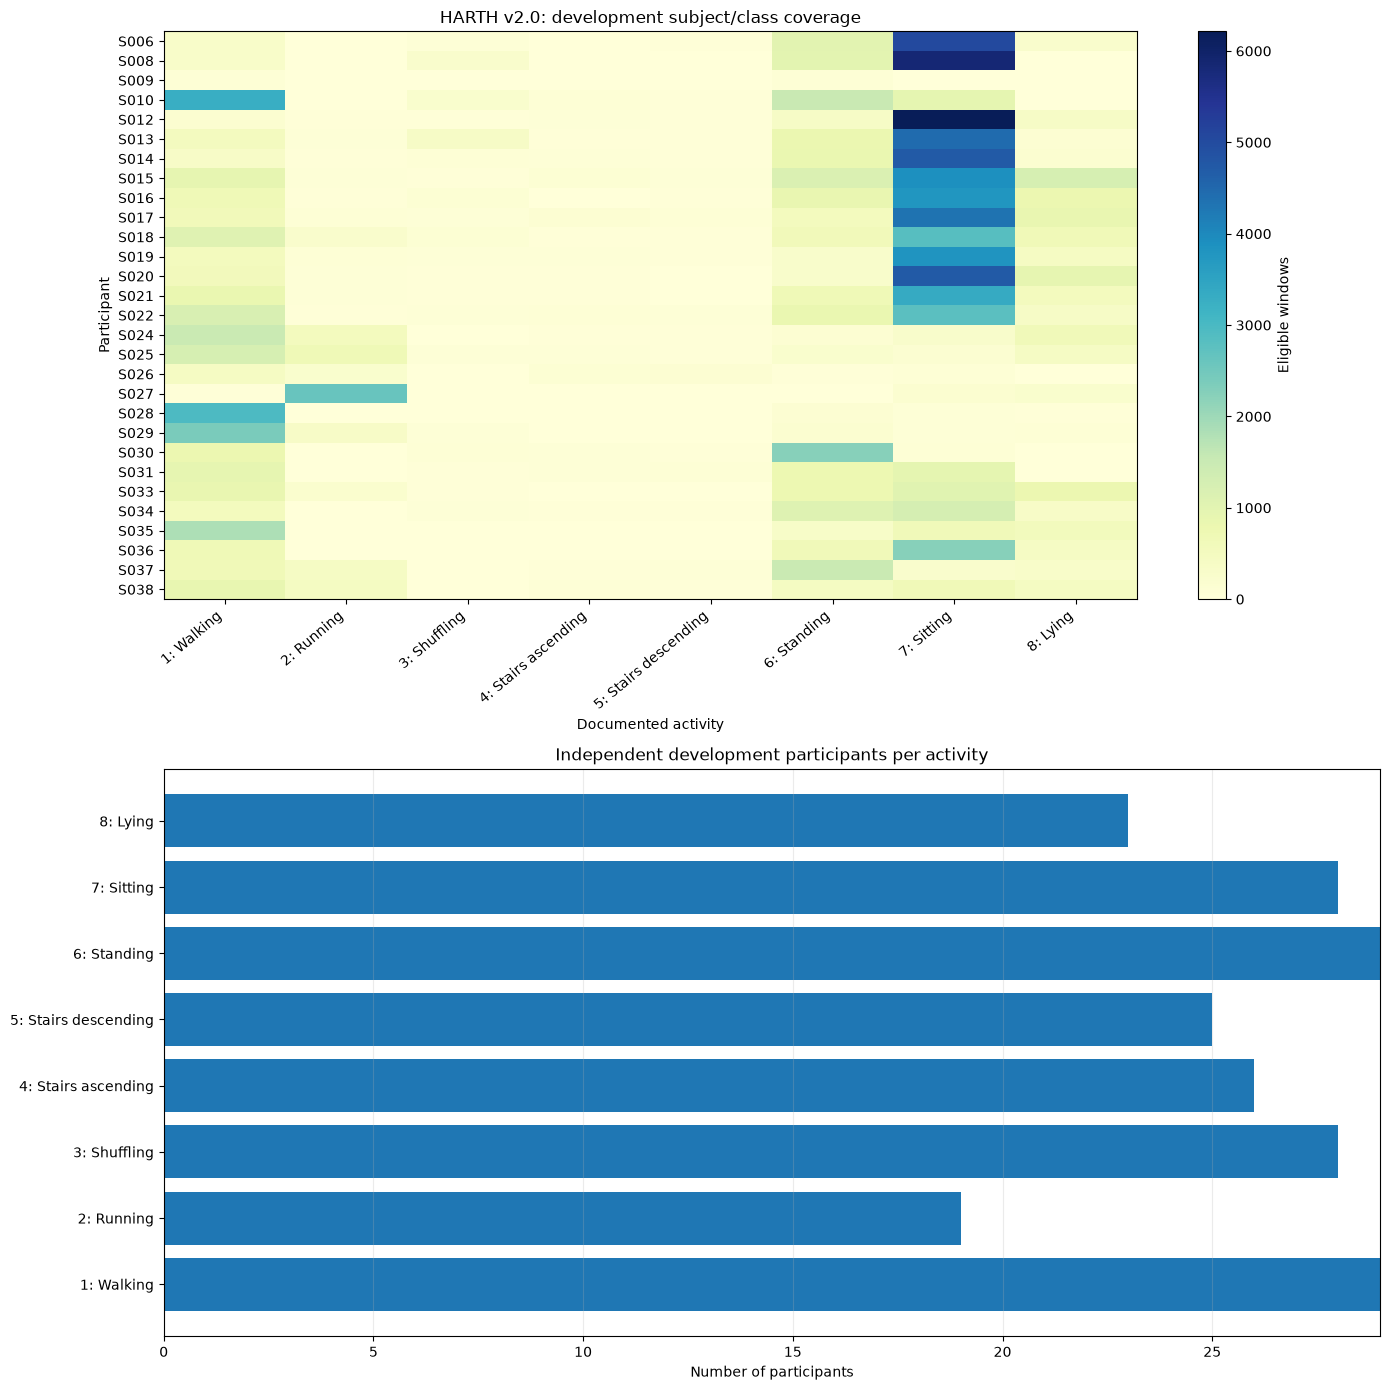

In [6]:
# ==================== 05. Visualise actual coverage ====================

# 1. Visualise person-by-class counts using the original units (windows).
fig, axes = plt.subplots(2, 1, figsize=(14, 14))
matrix = coverage.to_numpy()
heat = axes[0].imshow(matrix, aspect="auto", cmap="YlGnBu")
axes[0].set_xticks(np.arange(coverage.shape[1]), coverage.columns,
                   rotation=40, ha="right")
axes[0].set_yticks(np.arange(coverage.shape[0]), coverage.index)
axes[0].set(title="HARTH v2.0: development subject/class coverage",
            xlabel="Documented activity", ylabel="Participant")
fig.colorbar(heat, ax=axes[0], label="Eligible windows")

# 2. Count independent subjects, not windows, for each documented class.
subject_support = (coverage > 0).sum(axis=0)
axes[1].barh(subject_support.index, subject_support.to_numpy())
axes[1].set(title="Independent development participants per activity",
            xlabel="Number of participants", xlim=(0, len(DEVELOPMENT_SUBJECTS)))
axes[1].grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

**06. Quality gate and next decision**

Confirm that all planned development IDs have been processed and reserved Test IDs excluded. Then decide on a full-cohort grouped-CV protocol and preprocessing policy before training further models.

In [7]:
# ==================== 06. Quality gate and next decision ====================
# 1. Follow the documented quality gate and next decision procedure with the established dataset and checks.

# Verify subjects, feature integrity and fold membership in the audit.
assert metadata["subject_id"].nunique() == 29
assert not (set(metadata["subject_id"]) & RESERVED_TEST)
assert features.shape == (len(metadata), 30)
assert np.isfinite(features.to_numpy()).all()
assert len(folds) == 5
assert sum(overview["eligible_windows"]) == len(metadata)
assert sum(overview["excluded_windows"]) == sum(excluded["excluded_windows"])
print("Full development-cohort audit: PASSED")
print("Reserved Test participants used: NO")
print("Group-independent model fitting completed: NO")
print("Next: review class coverage, choose grouped evaluation, then train.")

Full development-cohort audit: PASSED
Reserved Test participants used: NO
Group-independent model fitting completed: NO
Next: review class coverage, choose grouped evaluation, then train.
